# RF-DETR Inference: Kalman Filter vs Particle Filter

This experiment compares two log-space state estimators on the same RF-DETR feed-area measurements:

1. **Kalman Filter** — fast Gaussian estimator with outlier rejection, RTS backward smoothing, and EMA.
2. **Particle Filter** — non-parametric Sequential Monte Carlo estimator with systematic resampling and a 95% credible interval.
3. **Controlled benchmark** — synthetic data with known latent truth for RMSE, MAE, interval coverage, and update-time comparisons.
4. **Video benchmark** — real RF-DETR measurements for responsiveness, temporal jitter, dropout stability, and update cost.
5. **Hunger assessment** — downstream consumption-rate analysis using the filter selected in `CONFIG['analysis_filter']`.

> The real-video RF-DETR areas do not provide ground truth. Therefore, distance to the raw measurement is reported as a
> **responsiveness proxy**, not as accuracy. Objective accuracy is evaluated only in the controlled synthetic experiment.

## tl;dr — saved 671-frame run

- Particle Filter measurement noise is now **0.675**, or **1.5×** the Kalman `sigma_R=0.45`; this makes it trust each RF-DETR detection less.
- In the degraded-detector synthetic stress test, Particle Filter log-RMSE was **0.3560** versus Kalman **0.4019** (11.4% lower), with 95% interval coverage of **97.7%** versus **85.7%**.
- On RF-DETR video measurements, Particle Filter reduced temporal jitter by **72.1%**, versus **62.8%** for online Kalman. Its larger distance from raw measurements is expected because the new setting intentionally discounts them.
- Particle Filter took **234 μs/frame**, about **28×** the online Kalman update, but remains small relative to RF-DETR inference at about **122 ms/frame**.

The real video has no annotated feed-area ground truth, so smoother behavior does not by itself prove greater real-world accuracy.

## 1. Setup and Configuration

In [1]:
import warnings
import os
import time

# Suppress transformers deprecation warnings
warnings.filterwarnings('ignore', message='.*use_return_dict.*')
warnings.filterwarnings('ignore', category=DeprecationWarning)

# Suppress transformers logging
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import logging
logging.getLogger('transformers').setLevel(logging.ERROR)
logging.getLogger('transformers.modeling_utils').setLevel(logging.ERROR)

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython import get_ipython
import pandas as pd
from pathlib import Path
import sys

# Render figures inside the saved notebook when running under Jupyter.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

# Register the system CJK font explicitly; Matplotlib may otherwise use a stale font cache.
CJK_FONT_PATH = '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc'
if os.path.exists(CJK_FONT_PATH):
    font_manager.fontManager.addfont(CJK_FONT_PATH)
    CJK_FONT_FAMILY = font_manager.FontProperties(fname=CJK_FONT_PATH).get_name()
else:
    CJK_FONT_FAMILY = 'DejaVu Sans'

# Shared, color-accessible plotting style
FILTER_COLORS = {
    'raw': '#6B7280',
    'kalman': '#2563EB',
    'particle': '#D97706',
    'truth': '#111827',
    'interval': '#FCD34D',
}
plt.rcParams.update({
    'font.sans-serif': [CJK_FONT_FAMILY, 'DejaVu Sans'],
    'axes.unicode_minus': False,
    'figure.figsize': (16, 6),
    'axes.grid': True,
    'grid.alpha': 0.22,
    'grid.linestyle': '--',
})

# Project imports (the notebook is intended to run from notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SRC_ROOT = PROJECT_ROOT / 'src'
for path in (SRC_ROOT, PROJECT_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from core.infer.rfdetr_detector import RFDETRDetector
from core.infer.kalman_filter import create_kalman_filter, KalmanFilterConfig
from core.types import CLASS_NAMES

print(f'✓ Imports successful (project root: {PROJECT_ROOT})')

✓ Imports successful (project root: /home/cliffyang/Program/Aquaculture_CV_Project)


In [2]:
# Configuration Parameters
CONFIG = {
    'video_path': PROJECT_ROOT / 'data/toilet1.mp4',
    'model_path': PROJECT_ROOT / 'models/rf-detr-fish-regular.pth',
    'confidence_threshold': 0.3,
    'device': 'cpu',
    'sigma_R': 0.45,       # Shared log-space measurement-noise std
    'sigma_Q': 0.25,       # Shared log-space process-noise std
    'particle_measurement_noise_scale': 1.5,  # >1 trusts RF-DETR measurements less
    'particle_outlier_threshold': 2.0,        # Keeps the robust gate conservative after inflating sigma_R
    'ema_alpha': 0.1,      # Kalman RTS post-smoothing EMA
    'max_missing_frames': 5,
    'particle_count': 2000,
    'particle_resample_ess_ratio': 0.5,
    'particle_seed': 20260525,
    'analysis_filter': 'kalman',  # 'kalman' (RTS+EMA) or 'particle' (online posterior median)
    'max_frames': None,
}

print('Configuration parameters:')
for key, value in CONFIG.items():
    print(f'  {key}: {value}')

Configuration parameters:
  video_path: /home/cliffyang/Program/Aquaculture_CV_Project/data/toilet1.mp4
  model_path: /home/cliffyang/Program/Aquaculture_CV_Project/models/rf-detr-fish-regular.pth
  confidence_threshold: 0.3
  device: cpu
  sigma_R: 0.45
  sigma_Q: 0.25
  particle_measurement_noise_scale: 1.5
  particle_outlier_threshold: 2.0
  ema_alpha: 0.1
  max_missing_frames: 5
  particle_count: 2000
  particle_resample_ess_ratio: 0.5
  particle_seed: 20260525
  analysis_filter: kalman
  max_frames: None


## 2. Load Model and Video

In [3]:
# Load RF-DETR detector
print(f'Loading RF-DETR model from: {CONFIG["model_path"]}')
detector = RFDETRDetector.load(
    model_path=str(CONFIG['model_path']),
    device=CONFIG['device'],
    conf_threshold=CONFIG['confidence_threshold'],
)
print(f'✓ Model loaded on device: {CONFIG["device"]}')
print(f'✓ Class names: {list(CLASS_NAMES)}')

Loading RF-DETR model from: /home/cliffyang/Program/Aquaculture_CV_Project/models/rf-detr-fish-regular.pth


/home/cliffyang/Program/Aquaculture_CV_Project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[2026-09-22 01:31:53] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-22 01:31:53] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-22 01:31:53] [WARNING] rf-detr - Checkpoint has 4 classes but model is configured for 90. Using checkpoint class count (4). Pass num_classes=4 to suppress this warning.
[2026-09-22 01:31:53] [WARNING] rf-detr - load_pretrain_weights: args.num_queries absent; inferred ckpt_num_queries=

✓ Model loaded on device: cpu
✓ Class names: ['debris', 'feed', 'fish', 'lumpfish']


In [4]:
# Load video
video_path = str(CONFIG['video_path'])
print(f'Loading video: {video_path}')
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError(f'Cannot open video: {video_path}')

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f'Video info:')
print(f'  Total frames: {total_frames}')
print(f'  FPS: {fps}')
print(f'  Resolution: {width}x{height}')
print(f'  Duration: {total_frames/fps:.2f} seconds')

Loading video: /home/cliffyang/Program/Aquaculture_CV_Project/data/toilet1.mp4
Video info:
  Total frames: 671
  FPS: 29.984359871899905
  Resolution: 720x1280
  Duration: 22.38 seconds


## 3. Filtering Methods

Both filters receive the same raw RF-DETR measurement stream and share `sigma_Q` plus the missing-frame policy. Because
RF-DETR feed detection is known to be less reliable, the Particle Filter deliberately uses
`particle_sigma_R = sigma_R × particle_measurement_noise_scale`. The default scale is **1.5**, so its measurement likelihood
is wider and each detection moves the posterior less. The robust innovation gate remains separate through
`particle_outlier_threshold`.

The Particle Filter operates in log-area space and performs systematic resampling when the effective sample size (ESS)
drops below the configured ratio. A fixed seed makes the experiment reproducible. Its point estimate is the posterior
median in area space, with weighted 2.5%/97.5% quantiles reported as a 95% credible interval.


In [5]:
class LogNormalParticleFilter:
    '''Bootstrap particle filter for positive feed-area measurements.'''

    def __init__(
        self,
        particle_count,
        sigma_R,
        sigma_Q,
        resample_ess_ratio=0.5,
        seed=0,
        max_missing_frames=5,
        reject_outliers=True,
        outlier_threshold=3.0,
    ):
        if particle_count < 100:
            raise ValueError('particle_count must be at least 100')
        if sigma_R <= 0 or sigma_Q < 0:
            raise ValueError('sigma_R must be > 0 and sigma_Q must be >= 0')
        if not 0 < resample_ess_ratio <= 1:
            raise ValueError('resample_ess_ratio must be in (0, 1]')

        self.particle_count = int(particle_count)
        self.sigma_R = float(sigma_R)
        self.sigma_Q = float(sigma_Q)
        self.resample_ess_ratio = float(resample_ess_ratio)
        self.max_missing_frames = int(max_missing_frames)
        self.reject_outliers = bool(reject_outliers)
        self.outlier_threshold = float(outlier_threshold)
        self.rng = np.random.default_rng(seed)

        self.particles_log = np.empty(0, dtype=float)
        self.weights = np.empty(0, dtype=float)
        self.initialized = False
        self.consecutive_missing = 0
        self.resample_count = 0
        self.outlier_rejection_count = 0
        self.estimate_history = []
        self.lower_history = []
        self.upper_history = []
        self.ess_history = []

    @staticmethod
    def _weighted_quantile(values, weights, quantiles):
        order = np.argsort(values)
        sorted_values = values[order]
        sorted_weights = weights[order]
        cumulative = np.cumsum(sorted_weights)
        cumulative /= cumulative[-1]
        return np.interp(quantiles, cumulative, sorted_values)

    def _effective_sample_size(self):
        return 1.0 / np.sum(np.square(self.weights))

    def _systematic_resample(self):
        positions = (self.rng.random() + np.arange(self.particle_count)) / self.particle_count
        indexes = np.searchsorted(np.cumsum(self.weights), positions, side='right')
        indexes = np.clip(indexes, 0, self.particle_count - 1)
        self.particles_log = self.particles_log[indexes]
        self.weights.fill(1.0 / self.particle_count)
        self.resample_count += 1

    def _record(self):
        if not self.initialized:
            estimate, lower, upper, ess = 0.0, 0.0, 0.0, 0.0
        else:
            q025, q50, q975 = self._weighted_quantile(
                self.particles_log,
                self.weights,
                np.array([0.025, 0.5, 0.975]),
            )
            estimate, lower, upper = np.exp([q50, q025, q975])
            ess = self._effective_sample_size()

        self.estimate_history.append(float(estimate))
        self.lower_history.append(float(lower))
        self.upper_history.append(float(upper))
        self.ess_history.append(float(ess))
        return float(estimate), float(lower), float(upper), float(ess)

    def update(self, area_measurement):
        '''Predict and update from one positive area measurement; zero means missing detection.'''
        area_measurement = float(area_measurement)

        if area_measurement <= 0:
            self.consecutive_missing += 1
            if self.initialized and self.consecutive_missing > self.max_missing_frames:
                self.particles_log += self.rng.normal(0.0, self.sigma_Q, self.particle_count)
            return self._record()

        measurement_log = np.log(area_measurement)
        self.consecutive_missing = 0

        if not self.initialized:
            self.particles_log = self.rng.normal(
                measurement_log,
                self.sigma_R,
                self.particle_count,
            )
            self.weights = np.full(self.particle_count, 1.0 / self.particle_count)
            self.initialized = True
            return self._record()

        # Random-walk transition in log space.
        self.particles_log += self.rng.normal(0.0, self.sigma_Q, self.particle_count)

        prior_mean = np.average(self.particles_log, weights=self.weights)
        prior_var = np.average((self.particles_log - prior_mean) ** 2, weights=self.weights)
        innovation_scale = np.sqrt(prior_var + self.sigma_R**2)
        is_outlier = (
            self.reject_outliers
            and abs(measurement_log - prior_mean) > self.outlier_threshold * innovation_scale
        )

        if is_outlier:
            self.outlier_rejection_count += 1
        else:
            standardized = (measurement_log - self.particles_log) / self.sigma_R
            log_likelihood = -0.5 * standardized**2
            log_likelihood -= np.max(log_likelihood)
            self.weights *= np.exp(log_likelihood)
            weight_sum = self.weights.sum()
            if not np.isfinite(weight_sum) or weight_sum <= 0:
                self.weights.fill(1.0 / self.particle_count)
            else:
                self.weights /= weight_sum

        if self._effective_sample_size() < self.resample_ess_ratio * self.particle_count:
            self._systematic_resample()

        return self._record()


print('✓ LogNormalParticleFilter defined')

✓ LogNormalParticleFilter defined


## 4. Run RF-DETR Inference with Both Filters

In [6]:
# Reload the Kalman module so this cell is safe after local code changes.
import importlib
import core.infer.kalman_filter as _kf_module
importlib.reload(_kf_module)
from core.infer.kalman_filter import create_kalman_filter, KalmanFilterConfig

# Re-open video (safe to re-run without re-running model loading cell).
cap = cv2.VideoCapture(str(CONFIG['video_path']))
if not cap.isOpened():
    raise ValueError(f'Cannot open video: {CONFIG["video_path"]}')
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

# Kalman keeps the baseline measurement noise; Particle Filter is deliberately less confident in RF-DETR.
kf_config = KalmanFilterConfig(
    sigma_R=CONFIG['sigma_R'],
    sigma_Q=CONFIG['sigma_Q'],
    reject_outliers=True,
    outlier_threshold=3.0,
    use_log_space=True,
    max_missing_frames=CONFIG['max_missing_frames'],
    ema_alpha=CONFIG['ema_alpha'],
)
kf = create_kalman_filter(kf_config)

particle_sigma_R = CONFIG['sigma_R'] * CONFIG['particle_measurement_noise_scale']
pf = LogNormalParticleFilter(
    particle_count=CONFIG['particle_count'],
    sigma_R=particle_sigma_R,
    sigma_Q=CONFIG['sigma_Q'],
    resample_ess_ratio=CONFIG['particle_resample_ess_ratio'],
    seed=CONFIG['particle_seed'],
    max_missing_frames=CONFIG['max_missing_frames'],
    reject_outliers=True,
    outlier_threshold=CONFIG['particle_outlier_threshold'],
)

frame_numbers = []
timestamps = []
detection_counts = []
feed_areas_raw = []
feed_areas_filtered = []
particle_areas = []
particle_ci_lower = []
particle_ci_upper = []
particle_ess = []
kalman_update_us = []
particle_update_us = []

max_frames = min(CONFIG['max_frames'] or total_frames, total_frames)
print(f'Starting inference on {max_frames} frames...')
print(f'Confidence threshold: {CONFIG["confidence_threshold"]}')
print(
    f'Kalman sigma_R={CONFIG["sigma_R"]}; Particle sigma_R={particle_sigma_R:.3f}; '
    f'sigma_Q={CONFIG["sigma_Q"]}; particles={CONFIG["particle_count"]}'
)

Starting inference on 671 frames...
Confidence threshold: 0.3
Kalman sigma_R=0.45; Particle sigma_R=0.675; sigma_Q=0.25; particles=2000


In [7]:
frame_idx = 0
detection_times = []

while frame_idx < max_frames:
    ret, frame = cap.read()
    if not ret:
        print(f'\nReached end of video at frame {frame_idx}')
        break

    detection_result = detector.detect(frame, frame_id=frame_idx)
    detection_times.append(detection_result.inference_ms)

    feed_detections = [d for d in detection_result.detections if d.class_name == 'feed']
    raw_area = sum(
        (det.bbox_w * width) * (det.bbox_h * height)
        for det in feed_detections
    )

    start_ns = time.perf_counter_ns()
    filtered_area = kf.update(
        raw_area,
        reject_outliers=kf_config.reject_outliers,
        outlier_threshold=kf_config.outlier_threshold,
    )
    kalman_update_us.append((time.perf_counter_ns() - start_ns) / 1_000.0)

    start_ns = time.perf_counter_ns()
    pf_area, pf_lower, pf_upper, pf_ess_value = pf.update(raw_area)
    particle_update_us.append((time.perf_counter_ns() - start_ns) / 1_000.0)

    frame_numbers.append(frame_idx)
    timestamps.append(frame_idx / fps)
    detection_counts.append(len(feed_detections))
    feed_areas_raw.append(raw_area)
    feed_areas_filtered.append(filtered_area)
    particle_areas.append(pf_area)
    particle_ci_lower.append(pf_lower)
    particle_ci_upper.append(pf_upper)
    particle_ess.append(pf_ess_value)

    if (frame_idx + 1) % 100 == 0:
        avg_latency = np.mean(detection_times[-100:])
        sys.stdout.write(
            f'\rProcessed: {frame_idx + 1}/{max_frames} frames '
            f'(RF-DETR avg latency: {avg_latency:.1f} ms)'
        )
        sys.stdout.flush()

    frame_idx += 1

cap.release()
print(f'\n\n✓ Inference complete: {len(frame_numbers)} frames')
print(f'RF-DETR mean latency: {np.mean(detection_times):.2f} ms/frame')

Processed: 600/671 frames (RF-DETR avg latency: 121.8 ms)

✓ Inference complete: 671 frames
RF-DETR mean latency: 122.94 ms/frame


In [8]:
# Kalman offline smoothing is kept separate from the online-filter comparison.
smoothed_areas = np.asarray(kf.rts_smooth(), dtype=float)
ema_areas, ema_log_areas = kf.apply_ema(smoothed_areas)
ema_areas = np.asarray(ema_areas, dtype=float)
ema_log_areas = np.asarray(ema_log_areas, dtype=float)

# Convert the shared experiment outputs once for downstream analysis.
frame_numbers = np.asarray(frame_numbers)
timestamps = np.asarray(timestamps)
detection_counts = np.asarray(detection_counts)
feed_areas_raw = np.asarray(feed_areas_raw, dtype=float)
feed_areas_filtered = np.asarray(feed_areas_filtered, dtype=float)
particle_areas = np.asarray(particle_areas, dtype=float)
particle_ci_lower = np.asarray(particle_ci_lower, dtype=float)
particle_ci_upper = np.asarray(particle_ci_upper, dtype=float)
particle_ess = np.asarray(particle_ess, dtype=float)
kalman_update_us = np.asarray(kalman_update_us, dtype=float)
particle_update_us = np.asarray(particle_update_us, dtype=float)

print('✓ Kalman RTS + EMA applied')
print(
    f'✓ Particle posterior collected with sigma_R={particle_sigma_R:.3f} '
    f'(confidence scale={CONFIG["particle_measurement_noise_scale"]:.2f}×); '
    f'resamples={pf.resample_count}, rejected outliers={pf.outlier_rejection_count}'
)

✓ Kalman RTS + EMA applied
✓ Particle posterior collected with sigma_R=0.675 (confidence scale=1.50×); resamples=76, rejected outliers=11


## 5. Controlled Synthetic Experiment

This stress test models the lower-confidence detector assumption by generating observations with
`sigma_R × particle_measurement_noise_scale`, plus random dropouts and gross outliers. Kalman retains its original
`sigma_R`; Particle Filter uses the inflated value. Since the latent trajectory is known, log-space RMSE/MAE are valid
accuracy measures. The 95% interval coverage checks uncertainty calibration, while median update time captures the
computational trade-off.


,Log_RMSE,Log_MAE,Coverage_95_Pct,Median_Update_us
Filter,,,,
Kalman Filter,0.4019,0.3233,85.7%,1.0
Particle Filter,0.3560,0.2857,97.7%,111.4


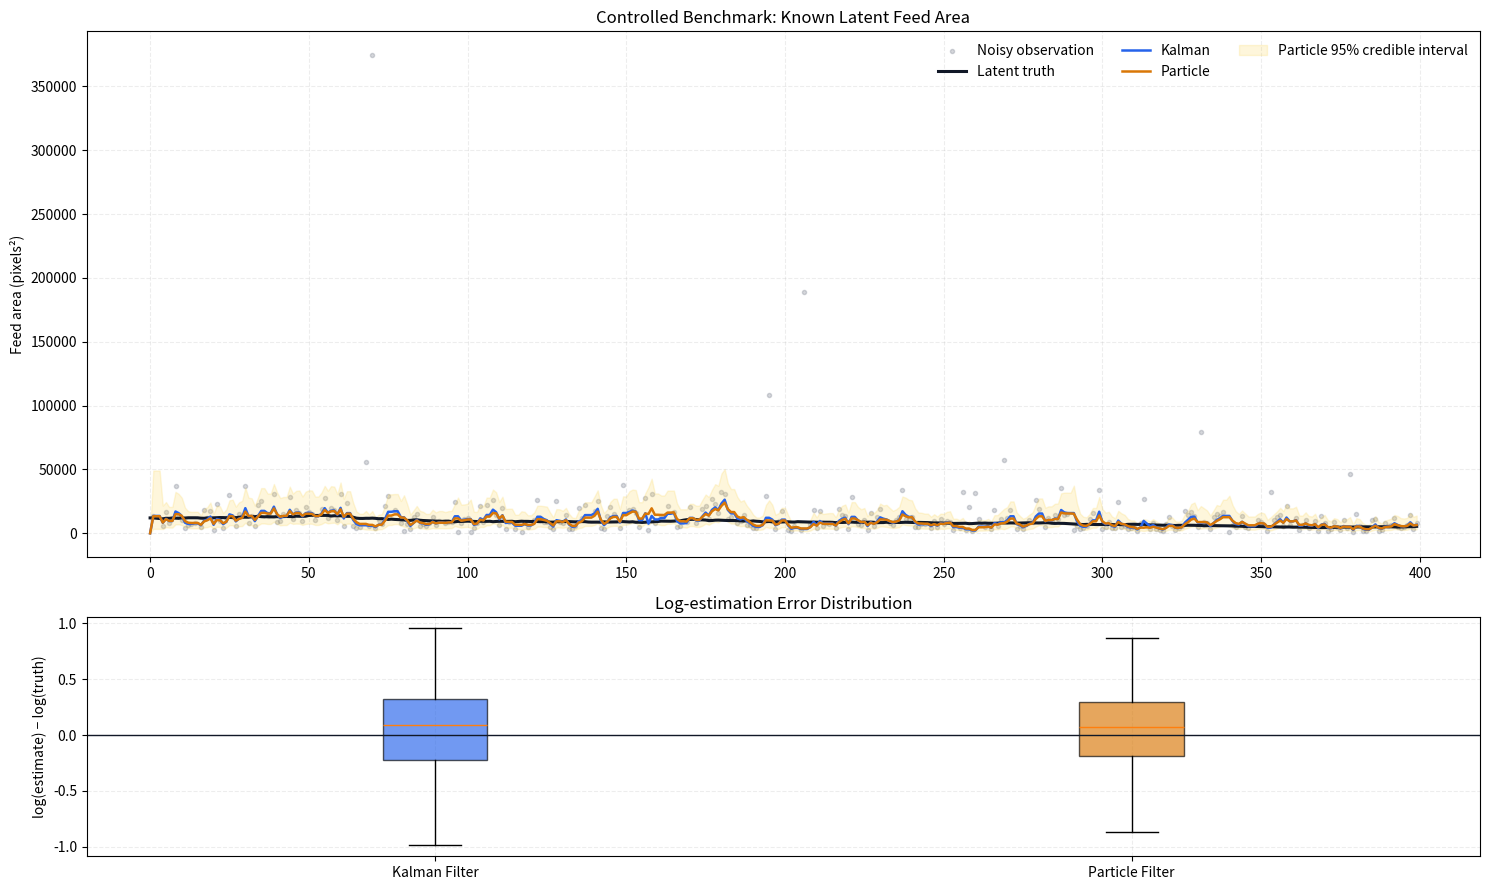

In [9]:
def run_synthetic_tracking_experiment(config, frame_count=400, seed=20260921):
    rng = np.random.default_rng(seed)

    # Smooth piecewise consumption/growth regimes plus small process variation.
    drift = np.r_[
        np.full(120, -0.0020),
        np.full(100, 0.0008),
        np.full(180, -0.0035),
    ][:frame_count]
    latent_log = np.log(12_000.0) + np.cumsum(drift + rng.normal(0.0, 0.018, frame_count))
    truth = np.exp(latent_log)
    particle_sigma_R = config['sigma_R'] * config['particle_measurement_noise_scale']
    observed_log = latent_log + rng.normal(0.0, particle_sigma_R, frame_count)
    observations = np.exp(observed_log)

    dropout_mask = rng.random(frame_count) < 0.12
    outlier_mask = (~dropout_mask) & (rng.random(frame_count) < 0.04)
    observations[dropout_mask] = 0.0
    observations[outlier_mask] *= np.exp(rng.choice([-2.0, 2.0], outlier_mask.sum()))

    synth_kf_config = KalmanFilterConfig(
        sigma_R=config['sigma_R'],
        sigma_Q=config['sigma_Q'],
        reject_outliers=True,
        outlier_threshold=3.0,
        use_log_space=True,
        max_missing_frames=config['max_missing_frames'],
        ema_alpha=config['ema_alpha'],
    )
    synth_kf = create_kalman_filter(synth_kf_config)
    synth_pf = LogNormalParticleFilter(
        particle_count=config['particle_count'],
        sigma_R=particle_sigma_R,
        sigma_Q=config['sigma_Q'],
        resample_ess_ratio=config['particle_resample_ess_ratio'],
        seed=config['particle_seed'] + 1,
        max_missing_frames=config['max_missing_frames'],
        reject_outliers=True,
        outlier_threshold=config['particle_outlier_threshold'],
    )

    kf_estimates, kf_lower, kf_upper, kf_times = [], [], [], []
    pf_estimates, pf_lower, pf_upper, pf_times = [], [], [], []

    for measurement in observations:
        start_ns = time.perf_counter_ns()
        kf_estimate = synth_kf.update(
            measurement,
            reject_outliers=synth_kf_config.reject_outliers,
            outlier_threshold=synth_kf_config.outlier_threshold,
        )
        kf_times.append((time.perf_counter_ns() - start_ns) / 1_000.0)
        kf_estimates.append(kf_estimate)

        if synth_kf.initialized:
            kf_std = np.sqrt(max(synth_kf.p_estimate, 0.0))
            kf_lower.append(np.exp(synth_kf.x_estimate - 1.96 * kf_std))
            kf_upper.append(np.exp(synth_kf.x_estimate + 1.96 * kf_std))
        else:
            kf_lower.append(0.0)
            kf_upper.append(0.0)

        start_ns = time.perf_counter_ns()
        pf_estimate, lower, upper, _ = synth_pf.update(measurement)
        pf_times.append((time.perf_counter_ns() - start_ns) / 1_000.0)
        pf_estimates.append(pf_estimate)
        pf_lower.append(lower)
        pf_upper.append(upper)

    arrays = {
        'truth': truth,
        'observations': observations,
        'dropout_mask': dropout_mask,
        'outlier_mask': outlier_mask,
        'kalman': np.asarray(kf_estimates),
        'kalman_lower': np.asarray(kf_lower),
        'kalman_upper': np.asarray(kf_upper),
        'particle': np.asarray(pf_estimates),
        'particle_lower': np.asarray(pf_lower),
        'particle_upper': np.asarray(pf_upper),
    }

    rows = []
    for name, estimate, lower, upper, timings in [
        ('Kalman Filter', arrays['kalman'], arrays['kalman_lower'], arrays['kalman_upper'], kf_times),
        ('Particle Filter', arrays['particle'], arrays['particle_lower'], arrays['particle_upper'], pf_times),
    ]:
        valid = estimate > 0
        log_error = np.log(estimate[valid]) - latent_log[valid]
        coverage = np.mean((truth[valid] >= lower[valid]) & (truth[valid] <= upper[valid]))
        rows.append({
            'Filter': name,
            'Log_RMSE': np.sqrt(np.mean(log_error**2)),
            'Log_MAE': np.mean(np.abs(log_error)),
            'Coverage_95_Pct': coverage * 100,
            'Median_Update_us': np.median(timings),
        })

    return arrays, pd.DataFrame(rows).set_index('Filter')


synthetic, synthetic_metrics_df = run_synthetic_tracking_experiment(CONFIG)
display(synthetic_metrics_df.style.format({
    'Log_RMSE': '{:.4f}',
    'Log_MAE': '{:.4f}',
    'Coverage_95_Pct': '{:.1f}%',
    'Median_Update_us': '{:.1f}',
}))

synthetic_frames = np.arange(len(synthetic['truth']))
fig, axes = plt.subplots(2, 1, figsize=(15, 9), gridspec_kw={'height_ratios': [2.2, 1]})
axes[0].scatter(
    synthetic_frames,
    np.where(synthetic['observations'] > 0, synthetic['observations'], np.nan),
    s=9,
    color=FILTER_COLORS['raw'],
    alpha=0.28,
    label='Noisy observation',
)
axes[0].plot(synthetic_frames, synthetic['truth'], color=FILTER_COLORS['truth'], linewidth=2.2, label='Latent truth')
axes[0].plot(synthetic_frames, synthetic['kalman'], color=FILTER_COLORS['kalman'], linewidth=1.8, label='Kalman')
axes[0].plot(synthetic_frames, synthetic['particle'], color=FILTER_COLORS['particle'], linewidth=1.8, label='Particle')
axes[0].fill_between(
    synthetic_frames,
    synthetic['particle_lower'],
    synthetic['particle_upper'],
    color=FILTER_COLORS['interval'],
    alpha=0.20,
    label='Particle 95% credible interval',
)
axes[0].set(title='Controlled Benchmark: Known Latent Feed Area', ylabel='Feed area (pixels²)')
axes[0].legend(ncol=3, frameon=False)

error_data = [
    np.log(synthetic['kalman'][synthetic['kalman'] > 0]) - np.log(synthetic['truth'][synthetic['kalman'] > 0]),
    np.log(synthetic['particle'][synthetic['particle'] > 0]) - np.log(synthetic['truth'][synthetic['particle'] > 0]),
]
box = axes[1].boxplot(error_data, tick_labels=['Kalman Filter', 'Particle Filter'], patch_artist=True, showfliers=False)
for patch, color in zip(box['boxes'], [FILTER_COLORS['kalman'], FILTER_COLORS['particle']]):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)
axes[1].axhline(0.0, color=FILTER_COLORS['truth'], linewidth=1)
axes[1].set(title='Log-estimation Error Distribution', ylabel='log(estimate) − log(truth)')
plt.tight_layout()
plt.savefig('rfdetr_synthetic_filter_benchmark.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Kalman vs Particle on RF-DETR Measurements

The video has no annotated feed-area ground truth. The following metrics therefore describe estimator behavior:

- **Log MAE to raw**: responsiveness proxy; lower is closer to RF-DETR, not necessarily more accurate.
- **Temporal jitter**: standard deviation of consecutive log changes on valid measurement pairs; lower is smoother.
- **Jitter reduction**: reduction relative to the raw valid-pair trajectory; higher is smoother.
- **Dropout drift**: mean absolute log change while RF-DETR reports zero; lower is more stable through missing detections.
- **Median update time**: filter-only compute cost, excluding RF-DETR inference.

,Log_MAE_to_Raw,Temporal_Jitter_Log_Std,Jitter_Reduction_vs_Raw_Pct,Dropout_Drift_Log,Median_Update_us
Filter,,,,,
Kalman Filter (online),0.1733,0.1864,62.8%,0.0000,9.3
Particle Filter (online),0.2175,0.1400,72.1%,0.0116,240.4


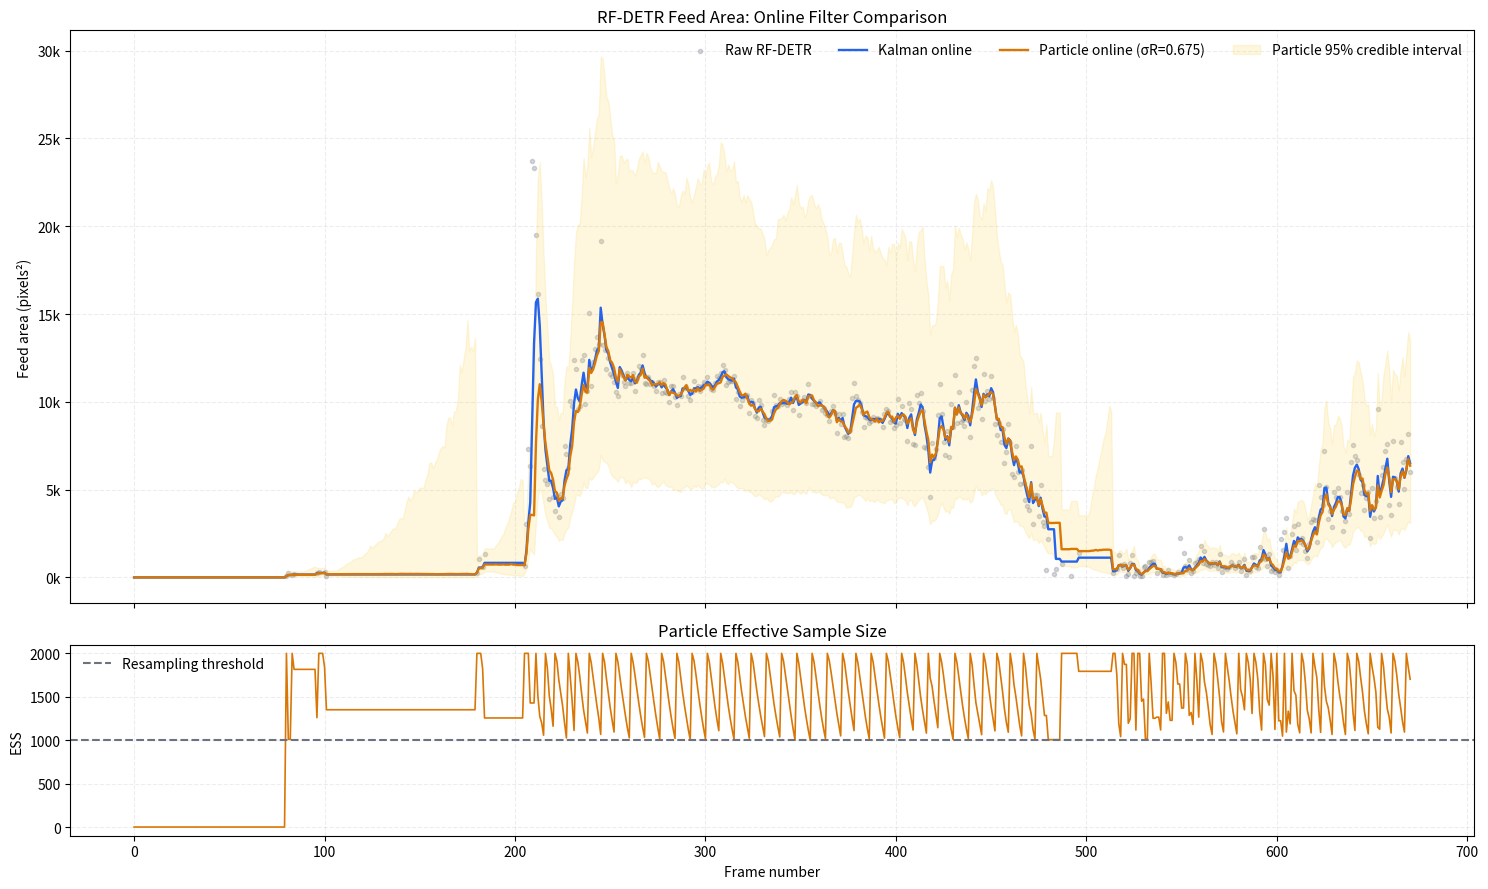

In [10]:
def behavior_metrics(name, estimates, update_times_us):
    estimates = np.asarray(estimates, dtype=float)
    valid = (feed_areas_raw > 0) & (estimates > 0)
    pair_valid = valid[1:] & valid[:-1]

    raw_log = np.full(feed_areas_raw.shape, np.nan)
    estimate_log = np.full(estimates.shape, np.nan)
    raw_log[feed_areas_raw > 0] = np.log(feed_areas_raw[feed_areas_raw > 0])
    estimate_log[estimates > 0] = np.log(estimates[estimates > 0])

    raw_steps = np.diff(raw_log)[pair_valid]
    estimate_steps = np.diff(estimate_log)[pair_valid]
    raw_jitter = np.std(raw_steps) if raw_steps.size else np.nan
    estimate_jitter = np.std(estimate_steps) if estimate_steps.size else np.nan

    missing_step_mask = (
        (feed_areas_raw[1:] <= 0)
        & (estimates[1:] > 0)
        & (estimates[:-1] > 0)
    )
    missing_steps = np.abs(np.diff(estimate_log)[missing_step_mask])

    return {
        'Filter': name,
        'Log_MAE_to_Raw': np.mean(np.abs(estimate_log[valid] - raw_log[valid])),
        'Temporal_Jitter_Log_Std': estimate_jitter,
        'Jitter_Reduction_vs_Raw_Pct': 100 * (1 - estimate_jitter / raw_jitter),
        'Dropout_Drift_Log': np.mean(missing_steps) if missing_steps.size else np.nan,
        'Median_Update_us': np.median(update_times_us),
    }


video_metrics_df = pd.DataFrame([
    behavior_metrics('Kalman Filter (online)', feed_areas_filtered, kalman_update_us),
    behavior_metrics('Particle Filter (online)', particle_areas, particle_update_us),
]).set_index('Filter')

display(video_metrics_df.style.format({
    'Log_MAE_to_Raw': '{:.4f}',
    'Temporal_Jitter_Log_Std': '{:.4f}',
    'Jitter_Reduction_vs_Raw_Pct': '{:.1f}%',
    'Dropout_Drift_Log': '{:.4f}',
    'Median_Update_us': '{:.1f}',
}))

fig, (ax_area, ax_ess) = plt.subplots(2, 1, figsize=(15, 9), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax_area.scatter(
    frame_numbers,
    np.where(feed_areas_raw > 0, feed_areas_raw, np.nan),
    s=9,
    color=FILTER_COLORS['raw'],
    alpha=0.28,
    label='Raw RF-DETR',
)
ax_area.plot(frame_numbers, feed_areas_filtered, color=FILTER_COLORS['kalman'], linewidth=1.7, label='Kalman online')
ax_area.plot(frame_numbers, particle_areas, color=FILTER_COLORS['particle'], linewidth=1.7, label=f'Particle online (σR={particle_sigma_R:.3f})')
ax_area.fill_between(
    frame_numbers,
    particle_ci_lower,
    particle_ci_upper,
    color=FILTER_COLORS['interval'],
    alpha=0.18,
    label='Particle 95% credible interval',
)
ax_area.set(title='RF-DETR Feed Area: Online Filter Comparison', ylabel='Feed area (pixels²)')
ax_area.legend(ncol=4, frameon=False)
ax_area.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value / 1000:.0f}k'))

ax_ess.plot(frame_numbers, particle_ess, color=FILTER_COLORS['particle'], linewidth=1.2)
ax_ess.axhline(
    CONFIG['particle_count'] * CONFIG['particle_resample_ess_ratio'],
    color=FILTER_COLORS['raw'],
    linestyle='--',
    label='Resampling threshold',
)
ax_ess.set(xlabel='Frame number', ylabel='ESS', title='Particle Effective Sample Size')
ax_ess.legend(frameon=False)
plt.tight_layout()
plt.savefig('rfdetr_filter_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 6.1 FFT-Based Low-Pass Filtering (Frequency-Domain Denoising)

As a third denoiser to compare against Kalman/Particle, we filter the raw RF-DETR feed-area
signal directly in the **frequency domain** using the Discrete Fourier Transform (DFT).

**Core idea.** A time-domain signal can be written as a sum of sinusoids of different
frequencies. Slow, physically meaningful feed-area changes live at *low* frequencies; per-frame
detection jitter and dropout spikes live at *high* frequencies. If we transform the signal into
the frequency domain, zero out the high-frequency components, and transform back, what remains is
a smoothed version of the original signal.

**1. Discrete Fourier Transform (DFT / FFT).** For a discrete signal $x[n]$, $n = 0, \dots, N-1$
(here, the raw feed-area measurement per frame), the DFT is

$$
X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-i 2\pi k n / N}, \qquad k = 0, \dots, N-1
$$

$X[k]$ is a complex number describing the amplitude and phase of the sinusoidal component at
frequency $f_k = k \cdot f_s / N$, where $f_s$ is the sampling rate (here, the video frame rate,
in samples/second). The FFT is simply an $O(N\log N)$ algorithm for computing the same quantity.

**2. Ideal low-pass filter (mask in the frequency domain).** We keep only frequency components
below a cutoff $f_c$ and remove the rest by multiplying $X[k]$ with a binary mask $H[k]$:

$$
H[k] = \begin{cases} 1, & |f_k| \le f_c \\ 0, & |f_k| > f_c \end{cases}
\qquad\qquad
Y[k] = H[k] \cdot X[k]
$$

By the **convolution theorem**, multiplying in the frequency domain is equivalent to convolving
$x[n]$ with the mask's inverse transform (a sinc-like kernel) in the time domain — i.e. this is a
(non-causal, zero-phase) moving-average-style smoother applied all at once via FFT, which is why
it introduces no lag relative to the raw signal, unlike an online EMA/Kalman filter.

**3. Inverse DFT (reconstruction).** The filtered signal is recovered by transforming back:

$$
y[n] = \frac{1}{N} \sum_{k=0}^{N-1} Y[k]\, e^{i 2\pi k n / N}
$$

Because the input is real-valued, we use `rfft`/`irfft` (the real-input DFT), which only computes
non-negative frequencies (exploiting Hermitian symmetry $X[-k] = X[k]^*$) and guarantees a
real-valued $y[n]$ without needing to discard numerical imaginary residue.

**4. Cutoff choice and Nyquist limit.** The highest representable frequency is the Nyquist
frequency $f_s / 2$. We pick $f_c \ll f_s/2$ so that only rapid, noise-like fluctuations (many
cycles per second) are removed while slower feed-consumption trends (cycles over many seconds)
pass through unattenuated.

**Caveats.**
- An *ideal* rectangular mask has a sinc-shaped time-domain response, so it can ring near sharp
  transitions (**Gibbs phenomenon**); we therefore also show a smoother Gaussian-tapered mask.
- The DFT assumes a complete, evenly-sampled series. RF-DETR dropouts (`raw_area == 0`) are gaps,
  not physical measurements of zero, so we linearly interpolate over them *before* the FFT — the
  same reason the Kalman filter treats dropouts as missing rather than as low readings.
- Unlike Kalman/Particle, this is an **offline, non-causal** filter: it uses the entire sequence
  at once (both past and future samples) and cannot run frame-by-frame online.


✓ FFT low-pass filter applied: fs=29.98 Hz, cutoff=1.499 Hz (Nyquist=14.99 Hz)


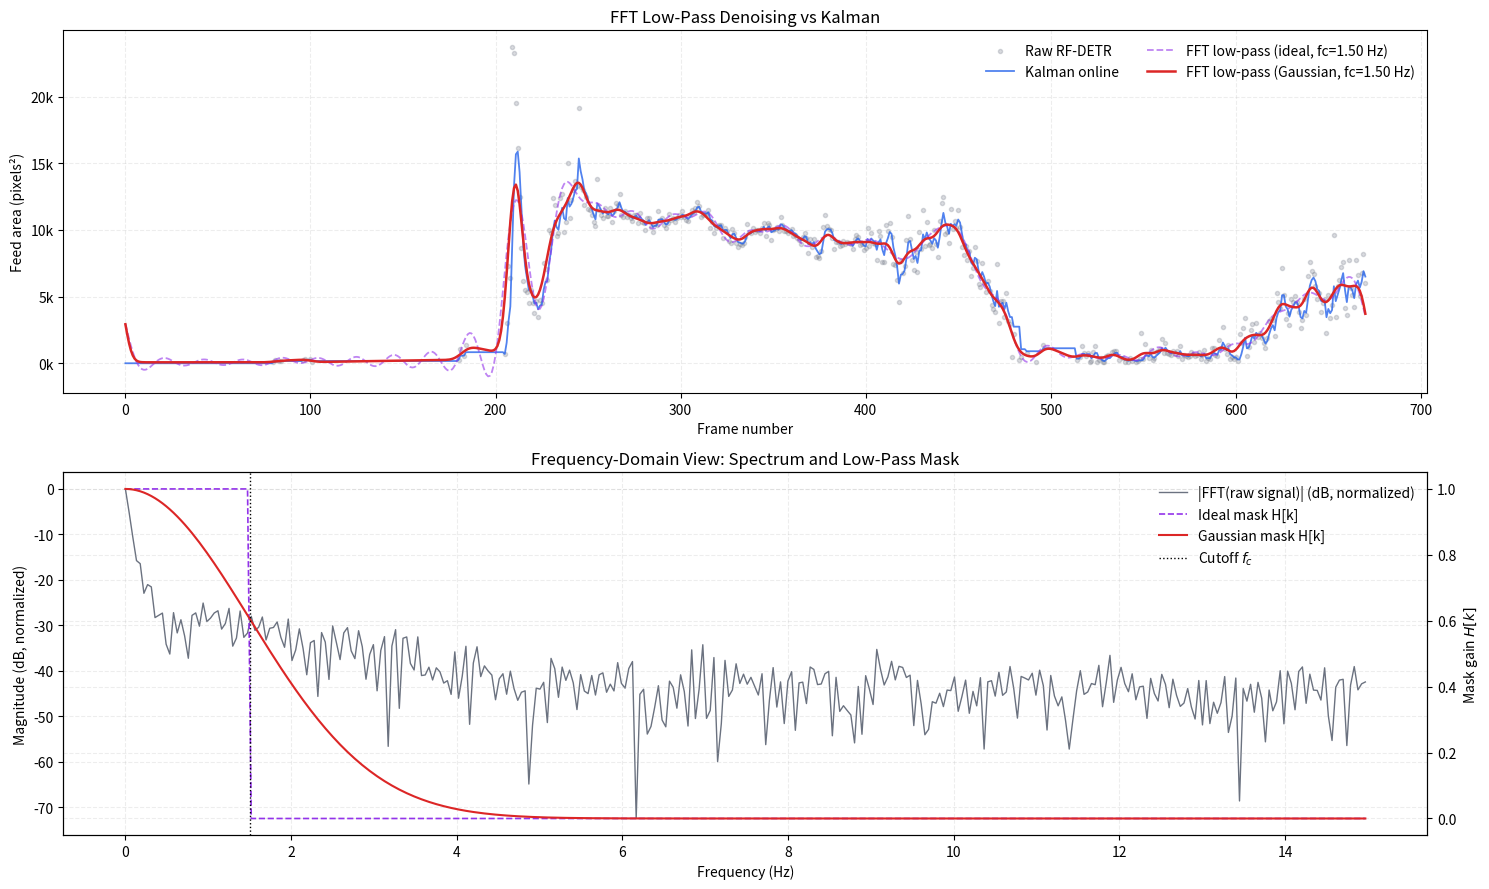

In [11]:
# FFT low-pass filter: forward FFT -> zero/taper high-frequency bins -> inverse FFT
from scipy.interpolate import interp1d

def fft_lowpass_filter(signal, sample_rate_hz, cutoff_hz, taper='gaussian'):
    '''Denoise a real 1D signal via FFT low-pass filtering (forward rFFT -> mask -> inverse rFFT).

    taper='ideal'    -> hard rectangular cutoff (can ring near sharp edges)
    taper='gaussian' -> smooth roll-off around cutoff_hz (avoids Gibbs ringing)
    '''
    n = len(signal)
    freqs = np.fft.rfftfreq(n, d=1.0 / sample_rate_hz)   # frequency of each DFT bin (Hz)
    spectrum = np.fft.rfft(signal)                         # forward FFT: time -> frequency

    if taper == 'ideal':
        mask = (freqs <= cutoff_hz).astype(float)
    else:
        # Gaussian mask: 1 at DC, ~0.5 at cutoff_hz, smoothly -> 0 for f >> cutoff_hz
        mask = np.exp(-0.5 * (freqs / cutoff_hz) ** 2)

    filtered_spectrum = spectrum * mask                   # apply low-pass mask (freq domain)
    filtered_signal = np.fft.irfft(filtered_spectrum, n=n)  # inverse FFT: frequency -> time
    return filtered_signal, freqs, spectrum, mask


# 1) Treat RF-DETR dropouts (raw_area == 0) as missing samples, not zero measurements,
#    and linearly interpolate so the FFT sees a complete, evenly-sampled series.
valid_mask = feed_areas_raw > 0
interp_fn = interp1d(
    frame_numbers[valid_mask],
    feed_areas_raw[valid_mask],
    kind='linear',
    bounds_error=False,
    fill_value=(feed_areas_raw[valid_mask][0], feed_areas_raw[valid_mask][-1]),
)
feed_areas_interp = interp_fn(frame_numbers).astype(float)

# 2) Cutoff frequency: keep slow feed-consumption trends, remove per-frame detection jitter.
#    Expressed as "at most this many oscillation cycles per second" of the feed-area signal.
FFT_CUTOFF_HZ = fps / 20.0  # e.g. at 30 fps -> 1.5 Hz cutoff (well below Nyquist = fps/2)

fft_areas_ideal, freqs, spectrum, mask_ideal = fft_lowpass_filter(
    feed_areas_interp, sample_rate_hz=fps, cutoff_hz=FFT_CUTOFF_HZ, taper='ideal',
)
fft_areas, _, _, mask_gauss = fft_lowpass_filter(
    feed_areas_interp, sample_rate_hz=fps, cutoff_hz=FFT_CUTOFF_HZ, taper='gaussian',
)

print(f'✓ FFT low-pass filter applied: fs={fps:.2f} Hz, cutoff={FFT_CUTOFF_HZ:.3f} Hz '
      f'(Nyquist={fps / 2:.2f} Hz)')

# 3) Visualize: (a) time-domain raw vs FFT-filtered vs Kalman, (b) frequency-domain spectrum + mask
fig, (ax_time, ax_freq) = plt.subplots(2, 1, figsize=(15, 9))

ax_time.scatter(frame_numbers, np.where(feed_areas_raw > 0, feed_areas_raw, np.nan),
                 s=9, color=FILTER_COLORS['raw'], alpha=0.25, label='Raw RF-DETR')
ax_time.plot(frame_numbers, feed_areas_filtered, color=FILTER_COLORS['kalman'],
             linewidth=1.3, alpha=0.8, label='Kalman online')
ax_time.plot(frame_numbers, fft_areas_ideal, color='#9333EA', linewidth=1.3, alpha=0.6,
             linestyle='--', label=f'FFT low-pass (ideal, fc={FFT_CUTOFF_HZ:.2f} Hz)')
ax_time.plot(frame_numbers, fft_areas, color='#DC2626', linewidth=1.8,
             label=f'FFT low-pass (Gaussian, fc={FFT_CUTOFF_HZ:.2f} Hz)')
ax_time.set(title='FFT Low-Pass Denoising vs Kalman', xlabel='Frame number', ylabel='Feed area (pixels²)')
ax_time.legend(ncol=2, frameon=False)
ax_time.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value / 1000:.0f}k'))

magnitude_db = 20 * np.log10(np.abs(spectrum) + 1e-9)
ax_freq.plot(freqs, magnitude_db - magnitude_db.max(), color=FILTER_COLORS['raw'], linewidth=1.0,
             label='|FFT(raw signal)| (dB, normalized)')
ax_freq_twin = ax_freq.twinx()
ax_freq_twin.plot(freqs, mask_ideal, color='#9333EA', linestyle='--', linewidth=1.2, label='Ideal mask H[k]')
ax_freq_twin.plot(freqs, mask_gauss, color='#DC2626', linewidth=1.5, label='Gaussian mask H[k]')
ax_freq_twin.axvline(FFT_CUTOFF_HZ, color='black', linestyle=':', linewidth=1, label='Cutoff $f_c$')
ax_freq_twin.set_ylabel('Mask gain $H[k]$')
ax_freq.set(title='Frequency-Domain View: Spectrum and Low-Pass Mask',
            xlabel='Frequency (Hz)', ylabel='Magnitude (dB, normalized)')
lines_a, labels_a = ax_freq.get_legend_handles_labels()
lines_b, labels_b = ax_freq_twin.get_legend_handles_labels()
ax_freq.legend(lines_a + lines_b, labels_a + labels_b, frameon=False, loc='upper right')

plt.tight_layout()
plt.savefig('rfdetr_fft_lowpass.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Feed Consumption and Hunger Metrics

In [12]:
def continuous_log_area(area_values):
    '''Create a log-area series without an artificial jump at first detection.'''
    area_values = np.asarray(area_values, dtype=float)
    positive = area_values > 0
    if not np.any(positive):
        return np.zeros_like(area_values)

    first = int(np.flatnonzero(positive)[0])
    logs = np.empty_like(area_values)
    logs[:first + 1] = np.log(area_values[first])
    for index in range(first + 1, len(area_values)):
        logs[index] = np.log(area_values[index]) if area_values[index] > 0 else logs[index - 1]
    return logs


kalman_analysis_areas = ema_areas
particle_analysis_areas = particle_areas
kalman_rate_log = np.diff(continuous_log_area(kalman_analysis_areas), prepend=continuous_log_area(kalman_analysis_areas)[0])
particle_rate_log = np.diff(continuous_log_area(particle_analysis_areas), prepend=continuous_log_area(particle_analysis_areas)[0])

selected_filter = str(CONFIG['analysis_filter']).strip().lower()
if selected_filter == 'kalman':
    analysis_filter_name = 'Kalman RTS + EMA'
    analysis_areas = kalman_analysis_areas
    consumption_rate_log = kalman_rate_log
elif selected_filter == 'particle':
    analysis_filter_name = 'Particle Filter (online posterior)'
    analysis_areas = particle_analysis_areas
    consumption_rate_log = particle_rate_log
else:
    raise ValueError("CONFIG['analysis_filter'] must be 'kalman' or 'particle'")

consumption_rate_pct = consumption_rate_log * 100
RATE_WINDOW = 30

def centered_window_average(values, window):
    half_window = window // 2
    return np.array([
        np.mean(values[max(0, i - half_window):min(len(values), i + half_window + (window % 2))])
        for i in range(len(values))
    ])

consumption_rate_log_avg = centered_window_average(consumption_rate_log, RATE_WINDOW)
consumption_rate_avg_pct = consumption_rate_log_avg * 100

print(f'Downstream analysis filter: {analysis_filter_name}')
print('Feed Area Statistics:')
print(f'  Raw min/max:              {feed_areas_raw.min():.0f} / {feed_areas_raw.max():.0f} pixels²')
print(f'  Kalman online min/max:    {feed_areas_filtered.min():.0f} / {feed_areas_filtered.max():.0f} pixels²')
print(f'  Kalman RTS+EMA min/max:   {ema_areas.min():.0f} / {ema_areas.max():.0f} pixels²')
print(f'  Particle online min/max:  {particle_areas.min():.0f} / {particle_areas.max():.0f} pixels²')

print(f'\nConsumption Rate Statistics ({analysis_filter_name}):')
print(f'  Mean: {consumption_rate_log.mean():.5f} /frame')
print(f'  Std:  {consumption_rate_log.std():.5f}')
print(f'  Min:  {consumption_rate_log.min():.5f} (fastest consumption)')
print(f'  Max:  {consumption_rate_log.max():.5f} (fastest growth)')
print(f'\nWindow-averaged rate (w={RATE_WINDOW}) std: {consumption_rate_log_avg.std():.5f}')

Downstream analysis filter: Kalman RTS + EMA
Feed Area Statistics:
  Raw min/max:              0 / 23734 pixels²
  Kalman online min/max:    0 / 15873 pixels²
  Kalman RTS+EMA min/max:   0 / 11451 pixels²
  Particle online min/max:  0 / 14536 pixels²

Consumption Rate Statistics (Kalman RTS + EMA):
  Mean: 0.00565 /frame
  Std:  0.03046
  Min:  -0.11166 (fastest consumption)
  Max:  0.17510 (fastest growth)

Window-averaged rate (w=30) std: 0.02315


### 7.1 Hunger Level Assessment

In [13]:
def assess_hunger_level(consumption_rate_log_avg):
    """
    Assess fish hunger level based on feed consumption rate.

    Hunger Levels:
    - 輕度 (Mild):     rate > -0.05   (slow/stable consumption)
    - 中度 (Moderate): -0.10 < rate ≤ -0.05 (active consumption)
    - 重度 (Severe):   rate ≤ -0.10   (very active consumption)
    """
    hunger_labels = []

    for local_rate in consumption_rate_log_avg:
        if local_rate > -0.05:
            hunger_labels.append('Mild (輕度)')
        elif local_rate > -0.1:
            hunger_labels.append('Moderate (中度)')
        else:
            hunger_labels.append('Severe (重度)')

    return hunger_labels

hunger_levels = assess_hunger_level(consumption_rate_log_avg)

hunger_counts = {}
for level in hunger_levels:
    hunger_counts[level] = hunger_counts.get(level, 0) + 1

print('Hunger Level Distribution:')
for level, count in sorted(hunger_counts.items(), key=lambda x: -x[1]):
    pct = (count / len(hunger_levels)) * 100
    print(f'  {level}: {count} frames ({pct:.1f}%)')

Hunger Level Distribution:
  Mild (輕度): 649 frames (96.7%)
  Moderate (中度): 22 frames (3.3%)


In [14]:
# Overall hunger assessment
overall_consumption = np.mean(consumption_rate_log_avg)

if overall_consumption > -0.05:
    overall_hunger = '輕度 (Mild)'
    hunger_color = 'green'
elif overall_consumption > -0.1:
    overall_hunger = '中度 (Moderate)'
    hunger_color = 'orange'
else:
    overall_hunger = '重度 (Severe)'
    hunger_color = 'red'

print(f'\nOverall Fish Hunger Assessment:')
print(f'  Hunger Level: {overall_hunger}')
print(f'  Average Consumption Rate: {overall_consumption:.5f} /frame')
print(f'  Consumption Intensity: {overall_consumption*100:.3f}% per frame')
print(f'  Video Duration Analyzed: {timestamps[-1]:.2f} seconds')


Overall Fish Hunger Assessment:
  Hunger Level: 輕度 (Mild)
  Average Consumption Rate: 0.00563 /frame
  Consumption Intensity: 0.563% per frame
  Video Duration Analyzed: 22.34 seconds


## 8. Visual Analysis

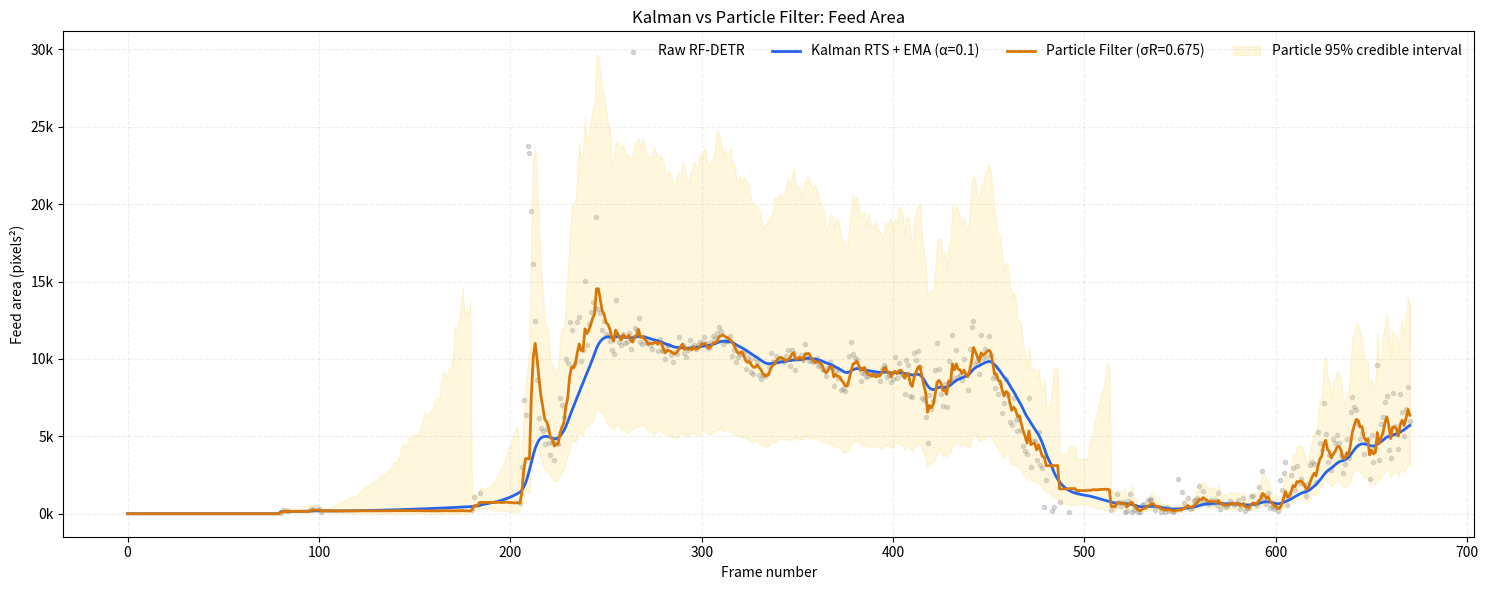

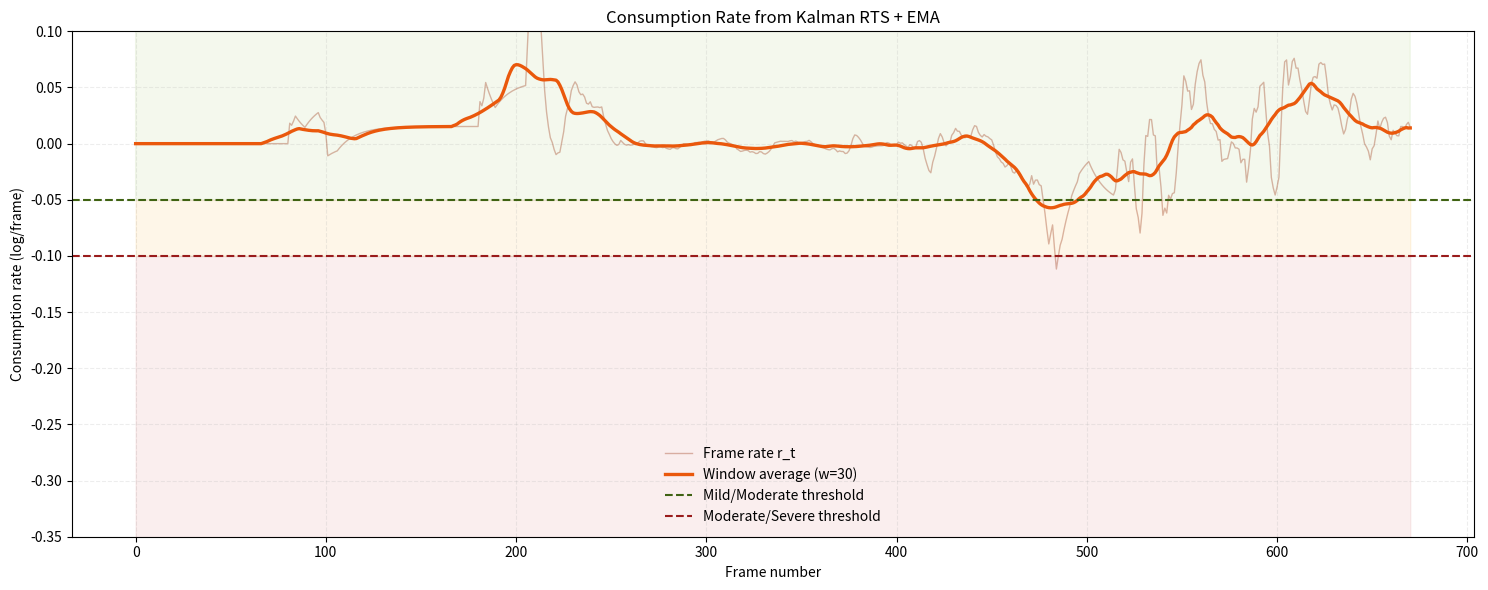

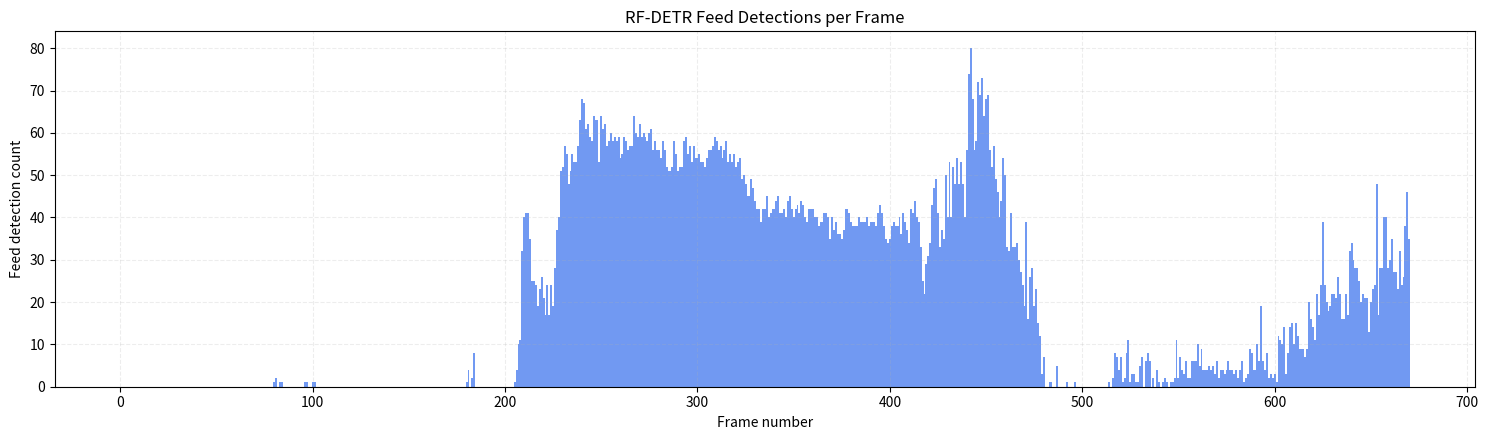

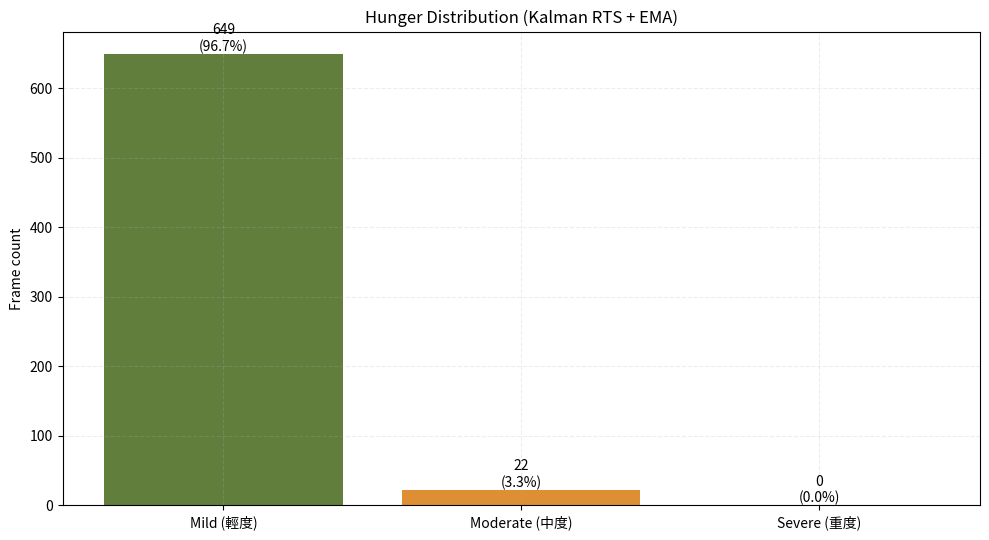

In [15]:
# Plot 1: final Kalman pipeline vs Particle Filter
fig1, ax1 = plt.subplots(figsize=(15, 6))
ax1.scatter(
    frame_numbers,
    np.where(feed_areas_raw > 0, feed_areas_raw, np.nan),
    label='Raw RF-DETR',
    color=FILTER_COLORS['raw'],
    alpha=0.25,
    s=9,
)
ax1.plot(frame_numbers, ema_areas, label=f'Kalman RTS + EMA (α={CONFIG["ema_alpha"]})', color=FILTER_COLORS['kalman'], linewidth=2)
ax1.plot(frame_numbers, particle_areas, label=f'Particle Filter (σR={particle_sigma_R:.3f})', color=FILTER_COLORS['particle'], linewidth=2)
ax1.fill_between(
    frame_numbers,
    particle_ci_lower,
    particle_ci_upper,
    color=FILTER_COLORS['interval'],
    alpha=0.18,
    label='Particle 95% credible interval',
)
ax1.set(xlabel='Frame number', ylabel='Feed area (pixels²)', title='Kalman vs Particle Filter: Feed Area')
ax1.legend(ncol=4, frameon=False)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value / 1000:.0f}k'))
plt.tight_layout()
plt.savefig('rfdetr_feed_area_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Plot 2: consumption rate for the selected downstream filter
fig2, ax2 = plt.subplots(figsize=(15, 6))
ax2.plot(frame_numbers, consumption_rate_log, color='#9A3412', linewidth=1.0, alpha=0.35, label='Frame rate r_t')
ax2.plot(frame_numbers, consumption_rate_log_avg, color='#EA580C', linewidth=2.4, label=f'Window average (w={RATE_WINDOW})')
ax2.axhline(-0.05, color='#3F6212', linestyle='--', linewidth=1.5, label='Mild/Moderate threshold')
ax2.axhline(-0.10, color='#991B1B', linestyle='--', linewidth=1.5, label='Moderate/Severe threshold')
ax2.fill_between(frame_numbers, -0.05, 0.5, alpha=0.07, color='#65A30D')
ax2.fill_between(frame_numbers, -0.10, -0.05, alpha=0.09, color='#F59E0B')
ax2.fill_between(frame_numbers, -0.5, -0.10, alpha=0.07, color='#B91C1C')
ax2.set(
    xlabel='Frame number',
    ylabel='Consumption rate (log/frame)',
    title=f'Consumption Rate from {analysis_filter_name}',
    ylim=(-0.35, 0.10),
)
ax2.legend(frameon=False)
plt.tight_layout()
plt.savefig('rfdetr_consumption_rate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Plot 3: feed detections per frame
fig3, ax3 = plt.subplots(figsize=(15, 4.5))
ax3.bar(frame_numbers, detection_counts, color=FILTER_COLORS['kalman'], alpha=0.65, width=1)
ax3.set(xlabel='Frame number', ylabel='Feed detection count', title='RF-DETR Feed Detections per Frame')
plt.tight_layout()
plt.savefig('rfdetr_detection_count_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Plot 4: hunger-level distribution
fig4, ax4 = plt.subplots(figsize=(10, 5.5))
ordered_levels = ['Mild (輕度)', 'Moderate (中度)', 'Severe (重度)']
level_counts = [hunger_counts.get(level, 0) for level in ordered_levels]
level_colors = ['#3F6212', '#D97706', '#991B1B']
bars = ax4.bar(ordered_levels, level_counts, color=level_colors, alpha=0.82)
ax4.set(ylabel='Frame count', title=f'Hunger Distribution ({analysis_filter_name})')
for bar, count in zip(bars, level_counts):
    ax4.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count}\n({count / len(hunger_levels) * 100:.1f}%)',
        ha='center',
        va='bottom',
    )
plt.tight_layout()
plt.savefig('rfdetr_hunger_distribution_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Detailed Hunger Timeline

✓ Saved: rfdetr_hunger_timeline.png


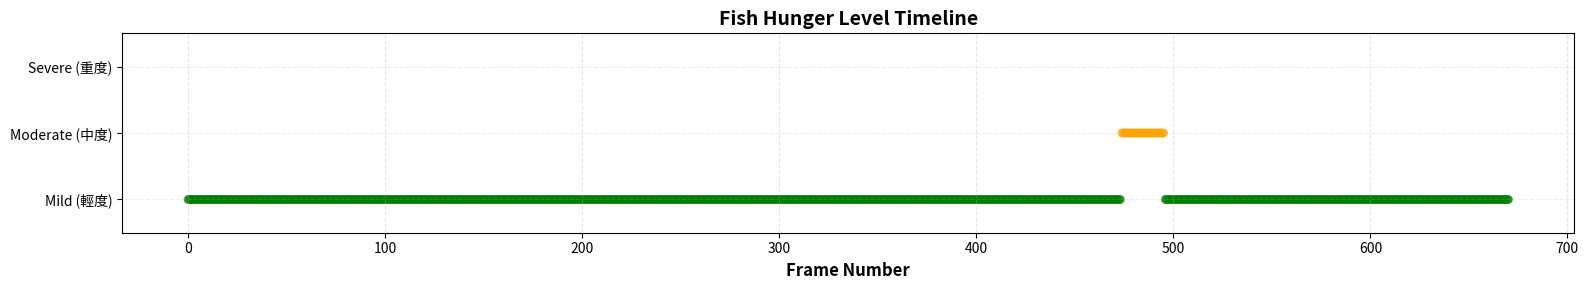

In [16]:
# Create hunger timeline visualization
fig, ax = plt.subplots(figsize=(16, 3))

# Map hunger levels to colors and numeric values
hunger_to_numeric = {'Mild (輕度)': 1, 'Moderate (中度)': 2, 'Severe (重度)': 3}
hunger_numeric = [hunger_to_numeric[level] for level in hunger_levels]
hunger_colors = {'Mild (輕度)': 'green', 'Moderate (中度)': 'orange', 'Severe (重度)': 'red'}

# Color each frame based on hunger level
colors = [hunger_colors[level] for level in hunger_levels]
ax.scatter(frame_numbers, hunger_numeric, c=colors, s=30, alpha=0.7)

ax.set_yticks([1, 2, 3])
ax.set_yticklabels(['Mild (輕度)', 'Moderate (中度)', 'Severe (重度)'])
ax.set_xlabel('Frame Number', fontsize=12, fontweight='bold')
ax.set_title('Fish Hunger Level Timeline', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
ax.set_ylim([0.5, 3.5])

plt.tight_layout()
plt.savefig('rfdetr_hunger_timeline.png', dpi=150, bbox_inches='tight')
print('✓ Saved: rfdetr_hunger_timeline.png')
plt.show()

## 10. Export Results

In [17]:
results_df = pd.DataFrame({
    'Frame': frame_numbers,
    'Time_sec': timestamps,
    'Raw_Feed_Area': feed_areas_raw,
    'Kalman_Online_Area': feed_areas_filtered,
    'Kalman_RTS_Area': smoothed_areas,
    'Kalman_RTS_EMA_Area': ema_areas,
    'Particle_Area': particle_areas,
    'Particle_CI_2_5': particle_ci_lower,
    'Particle_CI_97_5': particle_ci_upper,
    'Particle_ESS': particle_ess,
    'Kalman_Update_us': kalman_update_us,
    'Particle_Update_us': particle_update_us,
    'Kalman_Consumption_Rate_Log': kalman_rate_log,
    'Particle_Consumption_Rate_Log': particle_rate_log,
    'Selected_Analysis_Filter': analysis_filter_name,
    'Consumption_Rate_Log': consumption_rate_log,
    'Consumption_Rate_Pct': consumption_rate_pct,
    'Consumption_Rate_Log_Avg': consumption_rate_log_avg,
    'Consumption_Rate_Avg_Pct': consumption_rate_avg_pct,
    'Feed_Detection_Count': detection_counts,
    'Hunger_Level': hunger_levels,
})

csv_path = 'rfdetr_inference_results.csv'
results_df.to_csv(csv_path, index=False)
synthetic_metrics_df.to_csv('rfdetr_synthetic_filter_metrics.csv')
video_metrics_df.to_csv('rfdetr_video_filter_metrics.csv')
print(f'✓ Saved: {csv_path}')
print('✓ Saved: rfdetr_synthetic_filter_metrics.csv')
print('✓ Saved: rfdetr_video_filter_metrics.csv')

display(results_df.head(10))

✓ Saved: rfdetr_inference_results.csv
✓ Saved: rfdetr_synthetic_filter_metrics.csv
✓ Saved: rfdetr_video_filter_metrics.csv


,Frame,Time_sec,Raw_Feed_Area,Kalman_Online_Area,Kalman_RTS_Area,Kalman_RTS_EMA_Area,Particle_Area,Particle_CI_2_5,Particle_CI_97_5,Particle_ESS,...,Particle_Update_us,Kalman_Consumption_Rate_Log,Particle_Consumption_Rate_Log,Selected_Analysis_Filter,Consumption_Rate_Log,Consumption_Rate_Pct,Consumption_Rate_Log_Avg,Consumption_Rate_Avg_Pct,Feed_Detection_Count,Hunger_Level
0,0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,8.807,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
1,1,0.033351,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6.222,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
2,2,0.066701,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.811,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
3,3,0.100052,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.611,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
4,4,0.133403,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6.302,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
5,5,0.166754,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.348,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
6,6,0.200104,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.629,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
7,7,0.233455,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.228,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
8,8,0.266806,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.459,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)
9,9,0.300156,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.761,0.0,0.0,Kalman RTS + EMA,0.0,0.0,0.0,0.0,0,Mild (輕度)


## 11. Final Report

In [18]:
print('\n' + '=' * 78)
print('RF-DETR + KALMAN FILTER vs PARTICLE FILTER EXPERIMENT REPORT')
print('=' * 78)

print('\n【Experiment】')
print(f'  Video:                 {CONFIG["video_path"]}')
print(f'  Processed frames:      {len(frame_numbers)}')
print(f'  Duration:              {timestamps[-1]:.2f} seconds')
print(f'  RF-DETR mean latency:  {np.mean(detection_times):.2f} ms/frame')
print(f'  Kalman sigma_R:        {CONFIG["sigma_R"]}')
print(f'  Particle sigma_R:      {particle_sigma_R:.3f} ({CONFIG["particle_measurement_noise_scale"]:.2f}×)')
print(f'  Shared sigma_Q:        {CONFIG["sigma_Q"]}')
print(f'  PF outlier threshold:  {CONFIG["particle_outlier_threshold"]}σ')
print(f'  Particle count:        {CONFIG["particle_count"]}')
print(f'  PF resamples:          {pf.resample_count}')

print('\n【Controlled Synthetic Accuracy】')
print(synthetic_metrics_df.round(4).to_string())

print('\n【RF-DETR Video Behavior (no area ground truth)】')
print(video_metrics_df.round(4).to_string())
print('  Note: Log_MAE_to_Raw measures responsiveness, not accuracy.')

print('\n【Feed Area】')
print(f'  Raw RF-DETR:           {feed_areas_raw.min():,.0f} ~ {feed_areas_raw.max():,.0f} pixels²')
print(f'  Kalman online:         {feed_areas_filtered.min():,.0f} ~ {feed_areas_filtered.max():,.0f} pixels²')
print(f'  Kalman RTS + EMA:      {ema_areas.min():,.0f} ~ {ema_areas.max():,.0f} pixels²')
print(f'  Particle online:       {particle_areas.min():,.0f} ~ {particle_areas.max():,.0f} pixels²')

print('\n【Downstream Hunger Assessment】')
print(f'  Analysis filter:       {analysis_filter_name}')
print(f'  Overall hunger level:  {overall_hunger}')
print(f'  Mean consumption:      {overall_consumption:.5f} /frame')
for level in ['Mild (輕度)', 'Moderate (中度)', 'Severe (重度)']:
    count = hunger_counts.get(level, 0)
    print(f'    {level:20s}: {count:4d} frames ({count / len(hunger_levels) * 100:5.1f}%)')

print('\n【Output Files】')
for output_path in [
    'rfdetr_synthetic_filter_benchmark.png',
    'rfdetr_filter_comparison.png',
    'rfdetr_feed_area_analysis.png',
    'rfdetr_consumption_rate_analysis.png',
    'rfdetr_detection_count_analysis.png',
    'rfdetr_hunger_distribution_analysis.png',
    'rfdetr_hunger_timeline.png',
    'rfdetr_inference_results.csv',
    'rfdetr_synthetic_filter_metrics.csv',
    'rfdetr_video_filter_metrics.csv',
]:
    print(f'  ✓ {output_path}')

print('\n' + '=' * 78)
print('Experiment complete.')
print('=' * 78)


RF-DETR + KALMAN FILTER vs PARTICLE FILTER EXPERIMENT REPORT

【Experiment】
  Video:                 /home/cliffyang/Program/Aquaculture_CV_Project/data/toilet1.mp4
  Processed frames:      671
  Duration:              22.34 seconds
  RF-DETR mean latency:  122.94 ms/frame
  Kalman sigma_R:        0.45
  Particle sigma_R:      0.675 (1.50×)
  Shared sigma_Q:        0.25
  PF outlier threshold:  2.0σ
  Particle count:        2000
  PF resamples:          76

【Controlled Synthetic Accuracy】
                 Log_RMSE  Log_MAE  Coverage_95_Pct  Median_Update_us
Filter                                                               
Kalman Filter      0.4019   0.3233          85.7143            0.9620
Particle Filter    0.3560   0.2857          97.7444          111.4455

【RF-DETR Video Behavior (no area ground truth)】
                          Log_MAE_to_Raw  Temporal_Jitter_Log_Std  Jitter_Reduction_vs_Raw_Pct  Dropout_Drift_Log  Median_Update_us
Filter                                       

****## 12. Takeaways

1. **Lower measurement confidence:** `particle_measurement_noise_scale=1.5` widens the Particle Filter likelihood and credible interval, reducing the influence of individual RF-DETR detections.
2. **Noisy-detector stress test:** under the explicit higher-noise assumption, Particle Filter improved log-RMSE and produced better-calibrated uncertainty than the unchanged Kalman configuration.
3. **Video behavior:** Particle Filter became smoother and farther from raw detections, which is the intended trade-off; the real video still lacks ground truth for an accuracy conclusion.
4. **Compute:** Particle Filter is substantially slower than Kalman, although both filter costs remain negligible compared with RF-DETR inference.
5. **Usage:** downstream hunger analysis still defaults to `analysis_filter='kalman'`. Set it to `'particle'` when you want the lower-confidence Particle trajectory to drive the hunger metrics.